<a href="https://colab.research.google.com/github/achezganov/turtle-weight-prediction/blob/main/turtle_weight_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Модель для предсказания массы зеленых морских черепах

---

*Задача — обучить модель для прогнозирования массы черепах по измерениям, полученным с помощью компьютерного зрения.*

## Постановка задачи машинного обучения

---

Так как требуется определять массу черепах, мы прогнозируем непрерывное числовое значение. Следовательно, это задача регрессии.

Поле `weight` — целевая переменная (target).

Планируется использовать метрики:
- $MAE$ (основа для принятия решения о рекомендации модели);
- $MSE$;
- $MAPE$;
- $R^2$.

Для целевой популяции ***Chelonia mydas*** массой от **50** до **150** кг приемлемое значение метрики — $MAE <= 5$ кг.

Также важно учитывать разные возрастные группы и размеры черепах в относительных величинах. Для этого используем $MAPE$.

Приемлемым является значение $R^{2}_{test|val} >= 0.97$.

#### Описание данных

---

- `id` — идентификатор измерения.
- `binomial_name` — международное научное название вида черепахи.
- `registration_number` — регистрационный номер черепахи.
- `shell_length` — длина панциря, мм.
- `shell_width` — ширина панциря, мм.
- `head_length` — длина головы, мм.
- `head_width` — ширина головы, мм.
- `flipper_length_n` — длина одной ласты, мм. У черепах четыре ласты, поэтому в датасете четыре таких столбца, в названиях вместо n указан номер от 1 до 4.
- `flipper_width_n` — ширина одной ласты, мм. У черепах четыре ласты, поэтому в датасете четыре таких столбца, в названиях вместо n указан номер от 1 до 4.
- `circle_count` — количество колец роста на панцире черепахи.
- `measure_count` — количество измерений, которые произвели, прежде чем усреднить показатели черепахи и добавить их в таблицу.
- `shell_crack` — наличие трещин панциря.
- `timestamp` — время внесения данных о черепахе.
- `weight` — масса черепахи, кг.

## Подключение и настройка библиотек

---

##### **Устанавливаем дополнительные библиотеки**

In [ ]:
%pip install "numpy<2" "pandas>=1.5,<3" "scikit-learn==1.6.1" "ydata-profiling==4.17.0"
%pip install --upgrade "seaborn==0.13.2" "Pillow>=9.2"

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


##### **Импортируем необходимые библиотеки и модули**

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Lasso, LinearRegression, Ridge, SGDRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_absolute_percentage_error,
    mean_squared_error,
    r2_score,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, StandardScaler

from ydata_profiling import ProfileReport
import PIL

## Загрузка датасета

---

In [ ]:
# Загружаем данные
original = pd.read_csv('datasets/turtles.csv', sep='\t', decimal=',')

# Сохраняем оригинал
df = original.copy()

In [ ]:
# Общая информация о датасете
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8861 entries, 0 to 8860
Data columns (total 20 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   id                   8861 non-null   int64  
 1   binomial_name        8812 non-null   object 
 2   registration number  8832 non-null   object 
 3   shell_length         8774 non-null   float64
 4   shell_width          8861 non-null   int64  
 5   head_length          8715 non-null   float64
 6   head_width           8715 non-null   float64
 7   flipper_length_1     8861 non-null   int64  
 8   flipper_width_1      8861 non-null   int64  
 9   flipper_length_2     8861 non-null   int64  
 10  flipper_width_2      8861 non-null   int64  
 11  flipper_length_3     8760 non-null   float64
 12  flipper_width_3      8760 non-null   float64
 13  flipper_length_4     8760 non-null   float64
 14  flipper_width_4      8760 non-null   float64
 15  circle_count         8861 non-null   i

In [ ]:
# Выведем первые 5 наблюдений из датасета
df.head()

,id,binomial_name,registration number,shell_length,shell_width,head_length,head_width,flipper_length_1,flipper_width_1,flipper_length_2,flipper_width_2,flipper_length_3,flipper_width_3,flipper_length_4,flipper_width_4,circle_count,measure_count,shell_crack,timestamp,weight
0,20438,Caretta caretta,d89af72662f49ece4d09dec75a8b0166,700.0,381,112.0,82.0,356,205,331,185,270.0,180.0,273.0,144.0,63,3.0,NaN,1703159226,87.687
1,19034,Lepidochelys olivacea,1579c64777de4db1c16e8b7b0d19c45e,341.0,295,65.0,48.0,216,190,229,186,164.0,182.0,180.0,149.0,0,1.0,1.0,1689428175,26.949
2,24689,LEPIDOCHELYS OLIVACEA,bfcec01187569615087e4d777c44985a,408.0,343,71.0,70.0,308,224,285,232,264.0,179.0,268.0,176.0,0,3.0,NaN,1745783111,30.016
3,17945,Lepidochelys Olivacea,2c159675aa28f0ea566fce2090bf4c82,512.0,432,98.0,95.0,334,317,364,284,NaN,NaN,NaN,NaN,3,4.0,1.0,1677757151,33.917
4,24543,lepidochelys olivacea,ecd22499761e2ac56a6d8eb765ec566d,408.0,307,50.0,54.0,280,168,269,218,199.0,165.0,209.0,180.0,0,4.0,1.0,1744455613,28.511


**Комментарий:** Данные загружены правильно, соответствуют описанию. Единственное несоответствие — название поля `registration number`: оно отличается от заявленного. Обработаем его.

In [ ]:
# Исправление названия поля
df.rename(columns={'registration number': 'registration_number'}, inplace=True)

## Исследовательский анализ данных

---

#### 1. Какие черепахи представлены в датасете

---

Выведем все названия видов черепах, имеющихся в датасете.

In [ ]:
df['binomial_name'].value_counts()

binomial_name
Lepidochelys olivacea     3372
Chelonia mydas            2325
Caretta caretta            674
lepidochelys olivacea      416
Dermochelys coriacea       399
Eretmochelys imbricata     332
Lepidochelys Olivacea      285
chelonia mydas             252
Chelonia Mydas             177
LEPIDOCHELYS OLIVACEA      142
caretta caretta             90
CHELONIA MYDAS              75
Caretta Caretta             46
eretmochelys imbricata      41
dermochelys coriacea        40
CARETTA CARETTA             37
Eretmochelys Imbricata      28
Dermochelys Coriacea        27
Lepidochelys kempii         22
DERMOCHELYS CORIACEA        18
ERETMOCHELYS IMBRICATA       8
lepidochelys kempii          3
Lepidochelys Kempii          3
Name: count, dtype: int64

#### 2. Проводим отбор записей о нужном виде черепах

---

- Необходимо нормализовать содержмое поля `binomial_name`. Для этого мы
напишем небольшую функцию.

- Затем выберем  **"Chelonia mydas"**.

**Комментарий:** Данные по видам черепах представлены выше. Обнаружена ошибка в наименовании, требуется нормализация названия. Целевая группа составляет около $30$% от всего датасета (**Chelonia mydas**).

##### 2.1 **Реализация функции нормализации текстовых полей**

In [ ]:
def normalize_text_columns(df, columns):
    df = df.copy()

    for col in columns:
        df[col] = (
            df[col]
            .astype('string')
            .str.strip()
            .str.replace(r'\s+', ' ', regex=True)
            .str.lower()
        )

    return df

##### 2.2 **Нормализуем поле**

In [ ]:
df = normalize_text_columns(df, ['binomial_name'])
df['binomial_name'].value_counts()

binomial_name
lepidochelys olivacea     4215
chelonia mydas            2829
caretta caretta            847
dermochelys coriacea       484
eretmochelys imbricata     409
lepidochelys kempii         28
Name: count, dtype: Int64

##### 2.3 **Фильтруем по нужному виду, сохраняем записи только о chelonia mydas**

In [ ]:
df = df[df['binomial_name'] == 'chelonia mydas']
df['binomial_name'].value_counts()

binomial_name
chelonia mydas    2829
Name: count, dtype: Int64

#### 3. Определим признаки, которые можно использовать для решения задачи

---

Выведем матрицу корреляции с целевым значением, это упростит принятие решения об
удалении неинформативных полей.

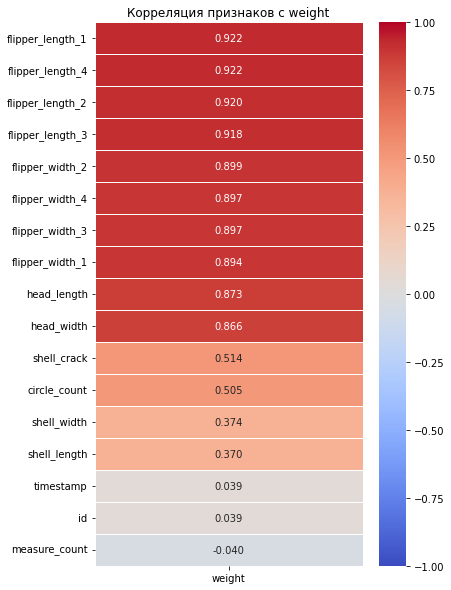

In [ ]:
# Матрица корреляции с полем weight
weight_corr = (
    df.corr(numeric_only=True)[['weight']]
    .drop(index='weight')
    .sort_values('weight', ascending=False)
    .round(3)
)

# Визуализация
plt.figure(figsize=(6, 10))

sns.heatmap(
    weight_corr,
    annot=True,
    cmap='coolwarm',
    fmt='.3f',
    linewidths=.5,
    vmin=-1,
    vmax=1
)

plt.title('Корреляция признаков с weight')
plt.show()

**Комментарий:**

Признаки, которые явно не смогут помочь:
- `id` — идентифицирующий признак.
- `binomial_name` — для задачи требуется только один вид, поэтому это поле также не имеет смысла оставлять.
- `timestamp` — также можно отнести к идентифицирующим признакам, но у него есть своя специфика. Так как корреляция очень слабая, смысла оставлять это поле я не вижу.
- `measure_count` — наблюдается слабая отрицательная корреляция, убираем.

- `registration_number` — потребуется нам для дедупликации, уберём его до этапа обработки.

Все остальные признаки имеют сильную или среднюю корреляцию и представляют интерес с точки зрения объяснения веса особи.

In [ ]:
# Удаляем ненужные поля
columns_to_drop = ['id', 'binomial_name', 'timestamp', 'measure_count']
df.drop(columns=columns_to_drop, inplace=True)

#### Профилирование

---

Для дальнейшей работы с датасетом проведём профилирование.

Вместо множества строк кода, направленных на тривиальную общенаправленную визуализацию, мы будем использовать профилирование. Поможет нам в этом библиотека `y-data-profiling`. [Ссылка](https://docs.profiling.ydata.ai/latest/)

In [ ]:
profile = ProfileReport(df, title="EDA Report")
profile

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 16/16 [00:00<00:00, 98.05it/s][A


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

#### 4. Исследование пропусков

---

Профилирование показало, что в данных есть пропуски.

Детально:

| Поле | Количество | Процент |
|---|---|---|
| `registration_number` | 4 | 0.1% |
| `shell_length` | 35 | 1.2% |
| `head_length` | 39 | 1.4% |
| `head_width` | 39 | 1.4% |
| `flipper_length_3` | 31 | 1.1% |
| `flipper_width_3` | 31 | 1.1% |
| `flipper_length_4` | 31 | 1.1% |
| `flipper_width_4` | 31 | 1.1% |
| `shell_crack` | 2152 | 76.1% |
| `weight` | 3 | 0.1% |

**Комментарий:**
Пропуски в поле `weight` недопустимы. В поле `shell_crack` пропуск означает отсутствие трещин. Основанием так полагать выступает вариативность данных этого поля, а именно `None, 1, 2, 3, 4, 5`. Конечно, мы не можем быть уверены, что 100% этих пропусков означают отсутствие трещин. Будем исходить из этой гипотезы, так как способов проверить это у нас нет.

Что касается остальных полей, содержащих пропуски, то, скорее всего, это системные сбои при сборе данных. С ними мы поработаем.

*Отберём строки, которые содержат хотя бы один пропуск, и посмотрим, какую долю от общего набора данных они занимают.*

In [ ]:
columns_with_missing = [
    'registration_number',
    'shell_length',
    'head_length',
    'head_width',
    'flipper_length_3',
    'flipper_width_3',
    'flipper_length_4',
    'flipper_width_4',
    'weight',
]

rows_with_missing = df.loc[df[columns_with_missing].isna().any(axis=1)]

In [ ]:
# Выводим долю строк с пропусками в выбранных полях
print(f'{len(rows_with_missing) / len(df) * 100:.2f}%')

3.85%


**Комментарий:**
Доля пропусков составляет $3.85$%$<5$%, поэтому можем от них безопасно избавиться путем заполнения медианным значением после разделения на выборки. Однако, можем заметить, что пропуски есть в целевой переменной `weight` их нельзя игнорировать, поэтому мы избавимся от них до разделения.

In [ ]:
df = df.dropna(subset=['weight']).copy()

Что касается поля `shell_crack`, пропуски там — не случайность: они означают отсутствие у черепах повреждений панциря. Поэтому их можно заменить на $0$ без потери смысловой нагрузки.

In [ ]:
# Заменяем пропуски shell_crack на 0
df['shell_crack'] = df['shell_crack'].fillna(0)

#### 5. Обработка дубликатов и исправление аномалий

---

Что касается неполных дубликатов, то их поиск в датасете, состоящем из персональных параметров тела черепахи, невозможен, так как все поля могут быть численно непрерывными и считать, что все они уникальны, корректно. У нас нет оснований «не доверять» `registration_number`, так как никаких уточнений от заказчика не было. Полагаем, что две черепахи с разными значениями `registration_number` и одинаковыми иными характеристическими показателями — разные черепахи. Если одна комбинация встретилась 10 раз, она получает больший статистический вес, чем комбинация, встретившаяся один раз.

Разумнее сначала исправить ошибки в значениях, а потом уже переходить к дедупликации, так как в процессе могут появиться новые дубликаты.

##### 5.1 **Исправление аномалий**

---

Нам известно, что в некоторых данных, связанных с параметрами тела, допущена ошибка, а именно: показатель завышен в **10 раз**. Именно от этой детали и будем отталкиваться. Также для опоры будем использовать зафиксированные исторические максимум и минимум.

У зелёной морской черепахи **Chelonia mydas** панцирь имеет сердцевидную или овальную форму, поэтому его длина всегда превышает ширину. Для этого вида соотношение пропорций обычно составляет около **4:3** или **5:4**. Рекордная длина — 60.2 in. (**1530** mm). [Ссылка](https://www.virginiaherpetologicalsociety.com/reptiles/turtles/green-sea-turtle/index.php)

Так как возраст самой молодой черепахи в наших данных составляет примерно 9 лет, длина панциря (карапакса) — от **450** mm. [Ссылка](https://repository.si.edu/server/api/core/bitstreams/f91e4c0f-dbe2-4cb3-9764-c7515f44073c/content)

**Комментарий:**

Аномальные значения, завышенные в 10 раз, могут быть обработаны ТОЛЬКО в полях `shell_length` и `shell_width`, так как в остальных полях не существует кейса, где $max_i >= min_i \cdot 10$, где $i$ — некоторое поле.

А что касается полей, отражающих размеры панциря, мы будем считать аномалиями те значения, что превосходят исторический минимум в 10 раз. Все остальные значения физически никак не могут быть связаны с ошибкой домножения на 10, иначе они пробьют исторический минимум, причём с большим отрывом.

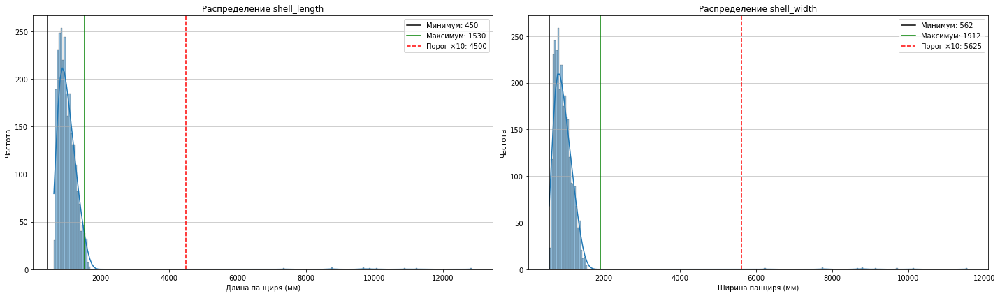

In [ ]:
# Константы
SHELL_L_HIST_MIN = 450
SHELL_L_HIST_MAX = 1530

SHELL_W_HIST_MIN = SHELL_L_HIST_MIN * 5 / 4
SHELL_W_HIST_MAX = SHELL_L_HIST_MAX * 5 / 4


# Визуализация
fig, axes = plt.subplots(1, 2, figsize=(20, 6))

plots = [
    ('shell_length', SHELL_L_HIST_MIN, SHELL_L_HIST_MAX, 'Длина панциря (мм)'),
    ('shell_width', SHELL_W_HIST_MIN, SHELL_W_HIST_MAX, 'Ширина панциря (мм)')
]

for ax, (col, hist_min, hist_max, xlabel) in zip(axes, plots):
    sns.histplot(df[col], kde=True, ax=ax)

    ax.axvline(hist_min, color='black', label=f'Минимум: {hist_min:.0f}')
    ax.axvline(hist_max, color='green', label=f'Максимум: {hist_max:.0f}')
    ax.axvline(hist_min * 10, color='red', linestyle='--',
               label=f'Порог ×10: {hist_min * 10:.0f}')

    ax.set_title(f'Распределение {col}')
    ax.set_xlabel(xlabel)
    ax.set_ylabel('Частота')
    ax.legend()
    ax.grid(axis='y', alpha=0.75)

plt.tight_layout()
plt.show()

**Комментарий:** В общем, заметно небольшое смещение распределения наших данных от биологических границ.

Если на этапе обучения результаты будут неудовлетворительными, можно попробовать использовать рамки исторических минимумов и максимумов для сокращения выборки.

Но я всё же склонен думать, что не стоит на этом заострять внимание.

##### **Реализация функции по исправлению аномалий**

In [ ]:
def correct_shell_dimensions(df):
    df = df.copy()
    df.loc[df['shell_length'] > SHELL_L_HIST_MIN * 10, 'shell_length'] /= 10
    df.loc[df['shell_width'] > SHELL_W_HIST_MIN * 10, 'shell_width'] /= 10

    return df

In [ ]:
# Сохраняем исправленные данные
df = correct_shell_dimensions(df)

##### 5.2 **Обработка дубликатов**

---

Используем для отбора признаки, по которым оцениваем полноту записи.
- `shell_crack` НЕ учитываем, потому что его NaN по смыслу означает 0.
- `registration_number` тоже не учитываем: он используется как ключ дедупликации.

In [ ]:
rows_before = len(df)

# Для каждой черепахи сохраняем первую запись
df = (
    df.drop_duplicates(subset='registration_number', keep='first')
    .reset_index(drop=True)
)

print(f'Удалено дубликатов: {rows_before - len(df)}')
print(f'Осталось строк: {len(df)}')

Удалено дубликатов: 343
Осталось строк: 2483


**Избавляемся от технического признака `registration_number`**

In [ ]:
df.drop(columns=['registration_number'], inplace=True)

#### 6. Обработка выбросов

---

Для формирования представления о выбросах ниже будут представлены гистограммы распределения значений и ящики с усами по числовым полям.

##### **Распределение характеристик панциря**

In [ ]:
def plot_distributions(data, feature_titles):

    """Строит гистограмму и ящик с усами"""

    fig, axes = plt.subplots(
        2, len(feature_titles),
        figsize=(5 * len(feature_titles), 6),
        sharex='col',
        squeeze=False,
        gridspec_kw={'height_ratios': [3, 1]},
    )

    for i, (column, title) in enumerate(feature_titles.items()):
        hist_ax = axes[0, i]
        box_ax = axes[1, i]

        sns.histplot(data[column], kde=True, ax=hist_ax)
        sns.boxplot(x=data[column], ax=box_ax)

        hist_ax.set_title(title)
        hist_ax.set_xlabel('')
        hist_ax.set_ylabel('Частота')
        hist_ax.grid(axis='y', alpha=0.5)

        box_ax.set_xlabel(title)
        box_ax.grid(axis='x', alpha=0.5)

    plt.tight_layout()
    plt.show()

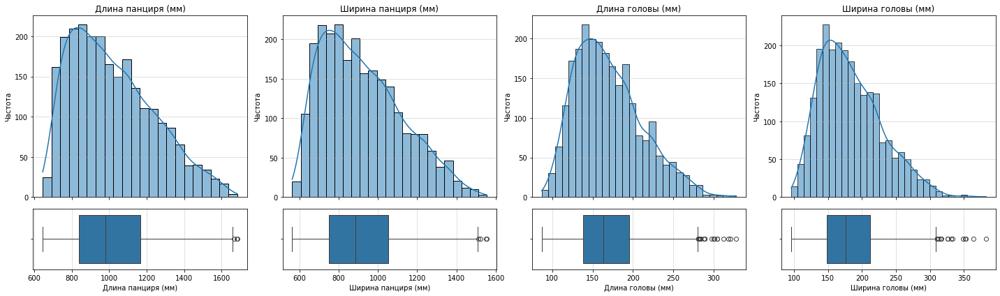

In [ ]:
body_features = {
    'shell_length': 'Длина панциря (мм)',
    'shell_width': 'Ширина панциря (мм)',
    'head_length': 'Длина головы (мм)',
    'head_width': 'Ширина головы (мм)',
}

plot_distributions(df, body_features)

**Комментарий:**
У `shell_length` и `shell_width` распределения плавно уходят вправо, а boxplot показывает буквально несколько точек за верхним усом. Это очень похоже на нормальную вариативность крупных особей.

У `head_length` и `head_width` выбросов визуально больше. Но здесь тоже нет обособленного второго кластера: гистограмма постепенно затухает вправо.

##### **Распределение характеристик ласт**

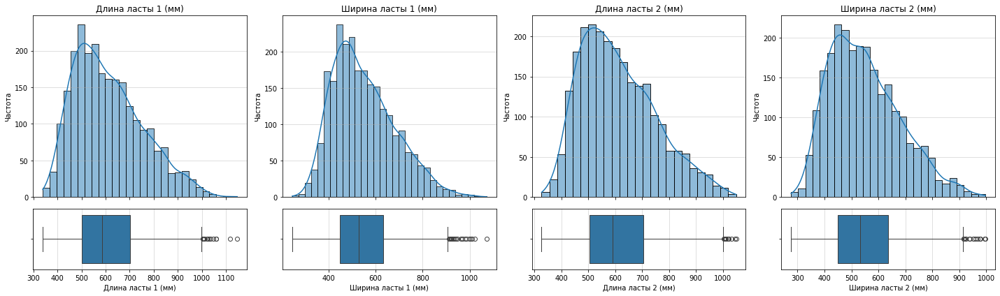

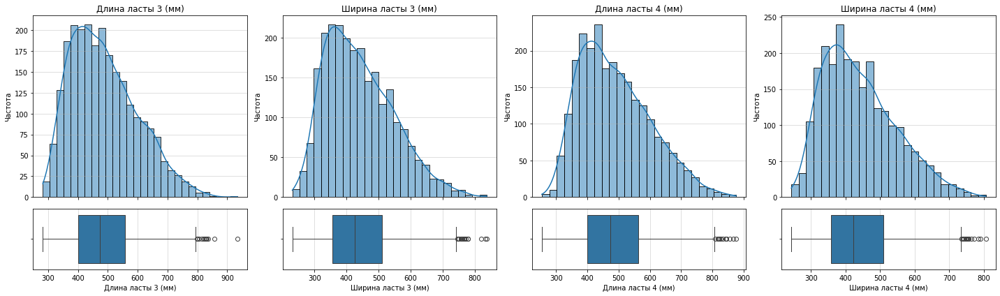

In [ ]:
flipper_features_1_2 = {
    'flipper_length_1': 'Длина ласты 1 (мм)',
    'flipper_width_1': 'Ширина ласты 1 (мм)',
    'flipper_length_2': 'Длина ласты 2 (мм)',
    'flipper_width_2': 'Ширина ласты 2 (мм)',
}
flipper_features_3_4 = {
    'flipper_length_3': 'Длина ласты 3 (мм)',
    'flipper_width_3': 'Ширина ласты 3 (мм)',
    'flipper_length_4': 'Длина ласты 4 (мм)',
    'flipper_width_4': 'Ширина ласты 4 (мм)',
}

plot_distributions(df, flipper_features_1_2)
plot_distributions(df, flipper_features_3_4)

**Комментарий:**
С ластами ситуация похожая. Распределения всех восьми признаков выраженно правосторонние, и точки за IQR-границей являются продолжением хвоста.

##### **Распределение веса и количества колец**

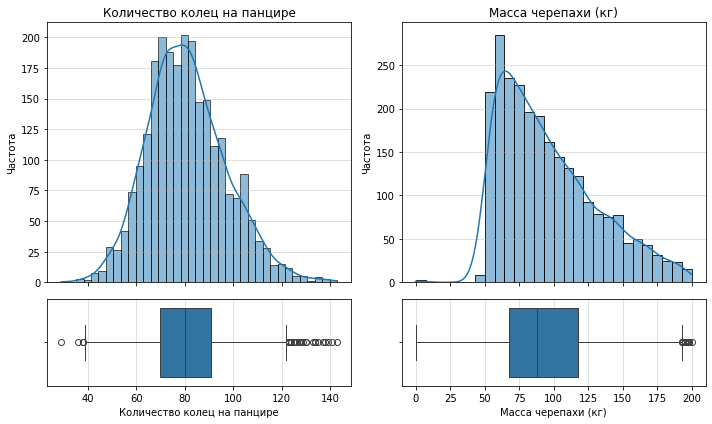

In [ ]:
remaining_features = {
    'circle_count': 'Количество колец на панцире',
    'weight': 'Масса черепахи (кг)',
}

plot_distributions(df, remaining_features)

**Комментарий:**

У `circle_count` распределение нормальное.

А вот у `weight` обнаружено нулевое значение. Разумеется, это невозможно игнорировать, и мы обработаем это недоразумение.

In [ ]:
# Удаляем записи с нулевой массой
df = df.loc[df['weight'] != 0].copy()
print(f'Количество строк после удаления записей с нулевой массой: {len(df)}')

Количество строк после удаления записей с нулевой массой: 2480


#### 7. Масштабы признаков

---

**Комментарий:**

В датасете присутствуют данные разных масштабов.

Также наблюдаются выбросы. Оснований полагать, что их природа неестественна, нет (ну, кроме того факта, что некоторые из них выходят за мировые рекорды, но я считаю, возможно, ошибочно, что это специфика задания, т. к. данные, скорее всего, могут иметь синтетическую природу; если это не так, то я, разумеется, приму меры по исправлению). Мы будем делать ставку на стандартизацию для масштабирования и на методы регуляризации.

#### 8. Обзор корреляций

----

Построим матрицу корреляции и сформируем выводы для дальнейшей работы.

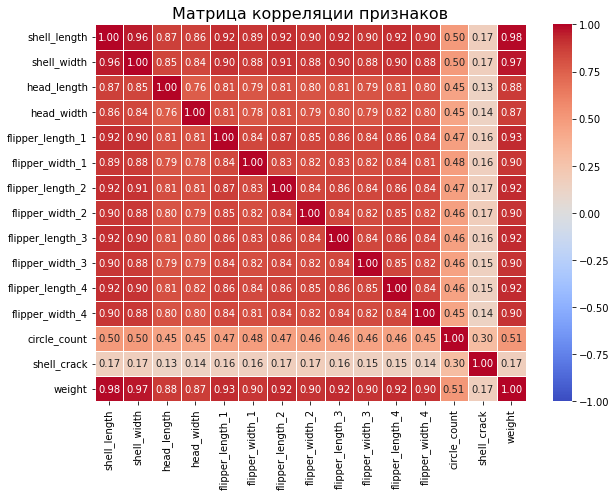

In [ ]:
# Вычисляем матрицу корреляции по всем оставшимся числовым признакам

features = [
    'shell_length', 'shell_width',
    'head_length', 'head_width',
    'flipper_length_1', 'flipper_width_1',
    'flipper_length_2', 'flipper_width_2',
    'flipper_length_3', 'flipper_width_3',
    'flipper_length_4', 'flipper_width_4',
    'circle_count', 'shell_crack',
    'weight',
]

corr = df[features].corr()

# Настраиваем размер графика
plt.figure(figsize=(9, 7))

# Строим тепловую карту
sns.heatmap(
    corr,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

plt.title('Матрица корреляции признаков', fontsize=16)
plt.tight_layout()
plt.show()

**Комментарий:**

Матрица показывает сильную положительную связь большинства морфометрических признаков с целевой переменной `weight`.

Наиболее высокая корреляция с весом наблюдается у следующих признаков:

`shell_length`, `shell_width`, `shell_length_*`, `shell_width_*`, `head_*`.

При этом сами морфометрические признаки также сильно коррелируют между собой.

`circle_count` имеет умеренную связь с `weight` (**0.50**) и не так сильно коррелирует с остальными признаками, поэтому может содержать дополнительную информацию.

`shell_crack` слабо связан как с `weight` (**0.16**), так и с другими признаками. Его можно рассматривать как кандидата на удаление.

#### 9. Проверка на мультиколлинеарность

---

Матрица корреляций указывает на выраженную мультиколлинеарность и частичное дублирование информации о размере черепахи.

При этом наиболее сильную связь с целевой переменной `weight` имеют:

- `shell_length` — **0.98**;
- `shell_width` — **0.97**;
- `shell_length_*` — **0.92–0.93**;
- `shell_width_*` — около **0.90**;
- `head_*` — **0.87**.

`shell_crack` в мультиколлинеарности практически не участвует.

Основная проблема — высокая взаимная корреляция признаков размеров тела. Мы вернёмся к решению проблемы мультиколлинеарности после разделения на выборки, чтобы принятые в процессе решения никак не компрометировали тестовую выборку.

## Предобработка данных

#### 1. Разделение данных на выборки

---

Разобьём данные на обучающую (60%), валидационную (20%) и тестовую (20%) выборки.

In [ ]:
X = df.drop(columns='weight')
y = df['weight']

# Выделяем 20% данных для тестовой выборки
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42,
)

# Четверть оставшихся 80% составляет 20% исходных данных
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.25, random_state=42,
)

for name, data in [
    ('обучающей', X_train),
    ('валидационной', X_val),
    ('тестовой', X_test),
]:
    print(f'Размер {name} выборки: {len(data)} ({len(data) / len(df):.0%})')

Размер обучающей выборки: 1488 (60%)
Размер валидационной выборки: 496 (20%)
Размер тестовой выборки: 496 (20%)


**Визуальное оценим качество распределения данных по выборкам**

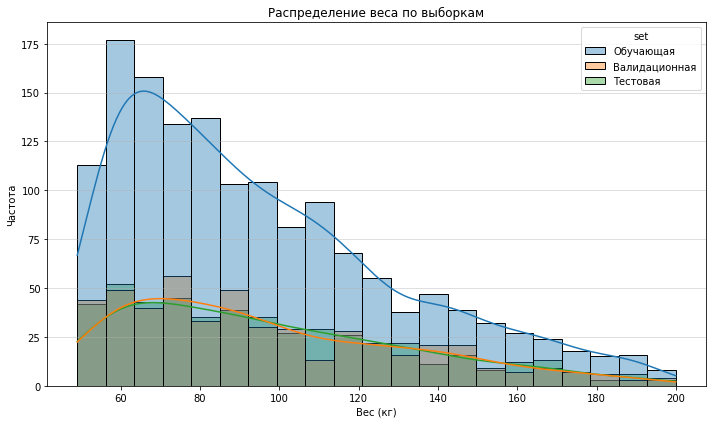

In [ ]:
plot_df_weight = pd.concat([
    y_train.rename('weight').to_frame().assign(set='Обучающая'),
    y_val.rename('weight').to_frame().assign(set='Валидационная'),
    y_test.rename('weight').to_frame().assign(set='Тестовая')
])

plt.figure(figsize=(10, 6))

sns.histplot(
    data=plot_df_weight,
    x='weight',
    hue='set',
    kde=True,
    alpha=0.4
)

plt.title('Распределение веса по выборкам')
plt.xlabel('Вес (кг)')
plt.ylabel('Частота')
plt.grid(axis='y', alpha=0.5)

plt.tight_layout()
plt.show()

**Комментарий:**  
Распределение целевого признака `weight` во всех трёх выборках имеет схожую форму: наблюдается правосторонняя асимметрия — основная часть объектов сосредоточена примерно в диапазоне 50–120 кг, а с увеличением веса частота наблюдений постепенно снижается.

Обучающая выборка имеет более высокие значения частот, что связано с её большим размером. При этом валидационная и тестовая выборки в целом повторяют форму распределения обучающей выборки.

Существенного смещения распределения `weight` между обучающей, валидационной и тестовой выборками визуально не наблюдается. Следовательно, разбиение данных по целевому признаку выглядит достаточно равномерным.

#### 2. Обработка пропущенных значений

По результатам EDA мы выяснили, что в данных содержатся пропуски, более того в важных для нас параметрах. Перед тем как переходить к сужению признакового пространство необходимо обработать пропуски.

In [ ]:
# Обзор на пропуски
X_train.isna().sum().sort_values(ascending=False)

shell_length        18
head_length         17
head_width          17
flipper_length_3    17
flipper_width_3     17
flipper_length_4    17
flipper_width_4     17
shell_width          0
flipper_length_1     0
flipper_width_1      0
flipper_length_2     0
flipper_width_2      0
circle_count         0
shell_crack          0
dtype: int64

**Комментарий:**

Пропуски появляются в менее чем в **3.5%** от всех данных (основано на EDA), мы можем заполнить их медианными значениями.

In [ ]:
# Рассчитываем медианы исключительно по X_train
train_medians = X_train.median()

# Заполняем пропуски
X_train = X_train.fillna(train_medians)
X_val = X_val.fillna(train_medians)
X_test = X_test.fillna(train_medians)

In [ ]:
# Количество пропусков по каждому признаку во всех выборках
missing_df = pd.DataFrame({
    'Train': X_train.isna().sum(),
    'Validation': X_val.isna().sum(),
    'Test': X_test.isna().sum()
})

missing_df

,Train,Validation,Test
shell_length,0,0,0
shell_width,0,0,0
head_length,0,0,0
head_width,0,0,0
flipper_length_1,0,0,0
flipper_width_1,0,0,0
flipper_length_2,0,0,0
flipper_width_2,0,0,0
flipper_length_3,0,0,0
flipper_width_3,0,0,0


#### Обработка мультиколлинеарности

---

Попробуем создать новые признаки, основываясь на текущих.

Масса тела обычно зависит не от одного линейного размера, а от объёма. А произведения размеров начинают приближать именно геометрию площади и объёма.

**Принцип образования новых признаков:**
1. `shell` = `shell_length` * `shell_width`;
2. `head` = `head_length` * `head_width`;
3. `flipper_1` = `flipper_length_1` * `flipper_width_1`;
4. `flipper_2` = `flipper_length_2` * `flipper_width_2`;
5. `flipper_3` = `flipper_length_3` * `flipper_width_3`;
6. `flipper_4` = `flipper_length_4` * `flipper_width_4`.

In [ ]:
# Пары признаков для объединения
features = {
    'shell': ('shell_length', 'shell_width'),
    'head': ('head_length', 'head_width'),
    'flipper_1': ('flipper_length_1', 'flipper_width_1'),
    'flipper_2': ('flipper_length_2', 'flipper_width_2'),
    'flipper_3': ('flipper_length_3', 'flipper_width_3'),
    'flipper_4': ('flipper_length_4', 'flipper_width_4')
}

# Создаём новые признаки во всех выборках
for data in (X_train, X_val, X_test):
    for new, (col_1, col_2) in features.items():
        data[new] = data[col_1] * data[col_2]

#### Проверка синтетических признаков

---

In [ ]:
# Копируем обучающие признаки
X_train_corr = X_train.copy()

# Временно добавляем целевую переменную
X_train_corr['weight'] = y_train

# Считаем корреляции только на обучающей выборке
correlations = X_train_corr.corr(numeric_only=True)['weight']

comparison_df = pd.DataFrame([
    {
        'Новый признак': new,
        'r (Новый)': correlations[new],
        'Компонент 1': comp_1,
        'r (Компонент 1)': correlations[comp_1],
        'Компонент 2': comp_2,
        'r (Компонент 2)': correlations[comp_2]
    }
    for new, (comp_1, comp_2) in features.items()
])

comparison_df['Новый лучше обоих?'] = (
    comparison_df['r (Новый)'].abs()
    > comparison_df[
        ['r (Компонент 1)', 'r (Компонент 2)']
    ].abs().max(axis=1)
)

comparison_df.round(4)

,Новый признак,r (Новый),Компонент 1,r (Компонент 1),Компонент 2,r (Компонент 2),Новый лучше обоих?
0,shell,0.9831,shell_length,0.9714,shell_width,0.9674,True
1,head,0.9251,head_length,0.8692,head_width,0.8700,True
2,flipper_1,0.9503,flipper_length_1,0.9289,flipper_width_1,0.8977,True
3,flipper_2,0.9534,flipper_length_2,0.9265,flipper_width_2,0.8999,True
4,flipper_3,0.9384,flipper_length_3,0.9126,flipper_width_3,0.8886,True
5,flipper_4,0.9418,flipper_length_4,0.9132,flipper_width_4,0.8911,True


**Комментарий:**

Все созданные признаки (`shell`, `head`, `flipper_1`–`flipper_4`) имеют более высокую корреляцию с `weight`, чем исходные длина и ширина по отдельности.

Наиболее сильную связь с весом показывает `shell`:

- `shell` — **0.9872**
- `shell_length` — **0.9846**
- `shell_width` — **0.9668**

Это подтверждает, что произведение длины и ширины лучше отражает общий размер части тела и может быть более информативным для прогнозирования массы.

Целесообразно оставить новые синтетические признаки, а исходные длину и ширину удалить, чтобы уменьшить избыточность и мультиколлинеарность.

In [ ]:
# Исходные признаки, заменённые синтетическими, и shell_crack
components_to_drop = [
    'shell_length', 'shell_width',
    'head_length', 'head_width',
    'flipper_length_1', 'flipper_width_1',
    'flipper_length_2', 'flipper_width_2',
    'flipper_length_3', 'flipper_width_3',
    'flipper_length_4', 'flipper_width_4',
    'shell_crack'
]

# Удаляем признаки из всех выборок
X_train = X_train.drop(columns=components_to_drop)
X_val = X_val.drop(columns=components_to_drop)
X_test = X_test.drop(columns=components_to_drop)

print('Исходные линейные признаки и shell_crack удалены.')
print(f'Оставшиеся признаки: {X_train.columns.tolist()}')

Исходные линейные признаки и shell_crack удалены.
Оставшиеся признаки: ['circle_count', 'shell', 'head', 'flipper_1', 'flipper_2', 'flipper_3', 'flipper_4']


**Комментарий:** Акцентирую также внимание на том, что среди удаляемых признаков присутствует `shell_crack`: у него слабая корреляция с целевым значением, и эмпирически было установлено, что он не влияет на итоговые метрики качества.

#### 3. Масштабирование признаков

---

Применяем функцию после разделения на выборки. Сохраняем три варианта данных: со стандартизацией, с нормализацией и без масштабирования.

На `train` стандартизация должна дать среднее около 0 и стандартное отклонение 1.

MinMax — минимум 0 и максимум 1. На `val/test` такие значения необязательны: MinMax может выходить за $[0, 1]$.

In [ ]:
def scale_features(X_train, X_val, X_test, method='standard'):

    if method == 'standard':
        # Параметры стандартизации по обучающей выборке
        mean = X_train.mean()
        std = X_train.std(ddof=0).replace(0, 1)

        X_train_scaled = (X_train - mean) / std
        X_val_scaled = (X_val - mean) / std
        X_test_scaled = (X_test - mean) / std

        scaler = {'mean': mean, 'std': std}

    elif method == 'minmax':
        # Параметры нормализации по обучающей выборке
        min_val = X_train.min()
        max_val = X_train.max()
        range_val = (max_val - min_val).replace(0, 1)

        X_train_scaled = (X_train - min_val) / range_val
        X_val_scaled = (X_val - min_val) / range_val
        X_test_scaled = (X_test - min_val) / range_val

        scaler = {'min': min_val, 'max': max_val}

    return X_train_scaled, X_val_scaled, X_test_scaled, scaler

In [ ]:
# Стандартизация
(
    X_train_scaled,
    X_val_scaled,
    X_test_scaled,
    standard_scaler
) = scale_features(X_train, X_val, X_test, method='standard')

# Масштабирование MinMax
(
    X_train_normalized,
    X_val_normalized,
    X_test_normalized,
    minmax_scaler
) = scale_features(X_train, X_val, X_test, method='minmax')

**Выполним проверку**

In [ ]:
scaling_check = pd.DataFrame({
    'Среднее после стандартизации': X_train_scaled.mean(),
    'Std после стандартизации': X_train_scaled.std(ddof=0),
    'Min после нормализации': X_train_normalized.min(),
    'Max после нормализации': X_train_normalized.max()
})

scaling_check.round(3)

,Среднее после стандартизации,Std после стандартизации,Min после нормализации,Max после нормализации
circle_count,-0.0,1.0,0.0,1.0
shell,-0.0,1.0,0.0,1.0
head,0.0,1.0,0.0,1.0
flipper_1,-0.0,1.0,0.0,1.0
flipper_2,-0.0,1.0,0.0,1.0
flipper_3,-0.0,1.0,0.0,1.0
flipper_4,-0.0,1.0,0.0,1.0


**Комментарий:** Проверка пройдена. Можно приступать к обучению.

## Обучение моделей

#### 0. Вспомогательные функции и инициализация

---

##### **Инициализация**

- `datasets` — список из трёх вариантов данных.
- `results` хранит строки с метриками.
- `trained_models` — обученные модели.

In [ ]:
datasets = [
    ('Без масштабирования', X_train, X_val),
    ('Стандартизация', X_train_scaled, X_val_scaled),
    ('MinMax', X_train_normalized, X_val_normalized)
]

results = []
trained_models = []

##### **Расчёт метрик**

In [ ]:
def calculate_metrics(y_true, y_pred):
    return {
        'MAE': mean_absolute_error(y_true, y_pred),
        'MSE': mean_squared_error(y_true, y_pred),
        'R2': r2_score(y_true, y_pred),
        'MAPE, %': mean_absolute_percentage_error(y_true, y_pred) * 100
    }

**Общая функция обучения**

*Так как, это центральная функция проекта, я решил оформить ее описание как текстовую ячейку.*

`train_models` получает три аргумента:
1. `model_class` — какую модель создать: например, Lasso.
2. `configurations` — список словарей с параметрами модели.
3. `data_variants` — варианты данных, на которых её нужно обучить.

Внутри два цикла: по данным и по конфигурациям. Для каждого сочетания создаётся
новая модель, выполняются fit, predict и расчёт метрик.

Результат и обученная модель добавляются в списки `results` и `trained_models` (Пункт с инициализацией выше).

Функция использует общие для всего эксперимента `y_train` и `y_val`.

`model_class(**parameters)` передаёт содержимое словаря как именованные параметры.
Например, для Lasso словарь `{'alpha': 0.1}` означает вызов `Lasso(alpha=0.1)`.

`model_class.__name__` даёт название класса для таблицы, например `'Lasso'`.

In [ ]:
def train_models(model_class, configurations, data_variants):

    for dataset_name, X_train_part, X_val_part in data_variants:
        for parameters in configurations:
            model = model_class(**parameters)
            model.fit(X_train_part, y_train)

            y_val_pred = model.predict(X_val_part)
            metrics = calculate_metrics(y_val, y_val_pred)
            metrics['Модель'] = model_class.__name__
            metrics['Датасет'] = dataset_name
            metrics['Параметры'] = str(parameters)
            if model_class in [Lasso, SGDRegressor]:
                metrics['Эпохи'] = model.n_iter_

            results.append(metrics)
            trained_models.append(model)

#### 1. Базовая модель (Dummy)

---

Выбираем `strategy='mean'`.

In [ ]:
train_models(
    DummyRegressor,
    [{'strategy': 'mean'}],
    datasets[:1]
)

#### 2. Обучение линейных моделей

---

##### **2.1 LinearRegression: три масштаба**

У этой модели нет параметра силы регуляризации `alpha` и нет шага SGD.
Поэтому её три конфигурации отличаются только масштабированием.

In [ ]:
# Используем стандартные параметры модели
train_models(LinearRegression, [{}], datasets)

##### **2.2 Lasso: масштаб и сила регуляризации**

Берём **0.01, 0.1, 1 и 10**: значения отличаются в 10 раз и позволяют сравнить
широкий диапазон силы штрафа.

In [ ]:
lasso_configurations = [
    {'alpha': 0.01, 'max_iter': 10000},
    {'alpha': 0.1, 'max_iter': 10000},
    {'alpha': 1.0, 'max_iter': 10000},
    {'alpha': 10.0, 'max_iter': 10000}
]

train_models(Lasso, lasso_configurations, datasets)

##### **2.3 Ridge: масштаб и сила регуляризации**

Для каждого масштаба проверяем те же **0.01, 0.1, 1 и 10**.

Оставляем стандартный выбор решателя `solver='auto'`, чтобы библиотека
выбрала подходящий способ решения для переданных данных.

In [ ]:
ridge_configurations = [
    {'alpha': 0.01},
    {'alpha': 0.1},
    {'alpha': 1.0},
    {'alpha': 10.0}
]

train_models(Ridge, ridge_configurations, datasets)

##### **2.4 SGDRegressor: обоснование параметров**

- **Потери:** сравниваем `squared_error` и `huber`. Huber слабее штрафует большие ошибки; `epsilon=5.0` задаёт порог 5 кг.
- **Регуляризация:** `penalty=None`, поскольку L1 и L2 проверяем через Lasso и Ridge.
- **Шаг:** `invscaling` постепенно его уменьшает. Проверяем `0.001` и `0.01` для масштабированных признаков, `1e-14` и `1e-13` — для крупных исходных.
- **Длительность:** сравниваем 1000 и 5000 эпох; `tol=None` отключает раннюю остановку.
- **Повторяемость:** `random_state=42` фиксирует перемешивание.

**Подготовка конфигураций SGD**

In [ ]:
# Создаём два списка конфигураций:
# для масштабированных и исходных признаков
sgd_scaled_configurations = []
sgd_raw_configurations = []

# Внешний цикл перебирает функции потерь,
# внутренний — четыре сочетания шага и числа проходов
for loss in ['squared_error', 'huber']:
    for eta0, epochs in [(0.001, 1000), (0.001, 5000),
                        (0.01, 1000), (0.01, 5000)]:
        parameters = {
            'loss': loss,
            'penalty': None,
            'learning_rate': 'invscaling',
            'eta0': eta0,
            'max_iter': epochs,
            'tol': None,
            'random_state': 42
        }
        if loss == 'huber':
            parameters['epsilon'] = 5.0
        sgd_scaled_configurations.append(parameters)

        # copy() чтобы смена шага не поменяла конфигурацию
        raw_parameters = parameters.copy()
        if eta0 == 0.001:
            raw_parameters['eta0'] = 1e-14
        else:
            raw_parameters['eta0'] = 1e-13
        sgd_raw_configurations.append(raw_parameters)

**Обучение SGD**

`datasets[:1]` берёт только первый вариант — исходные данные.

`datasets[1:]` берёт оставшиеся два — стандартизацию и нормализацию.

In [ ]:
# В обоих вызовах проверяются squared_error и huber
train_models(SGDRegressor, sgd_raw_configurations, datasets[:1])
train_models(SGDRegressor, sgd_scaled_configurations, datasets[1:])

#### 3. Итоговая таблица

---

В таблице 52 конфигурации:
- 1 Dummy
- 3 LinearRegression
- 12 Lasso
- 12 Ridge
- 24 SGD

In [ ]:
df_results = pd.DataFrame(results)
df_results = df_results[
    ['Модель', 'Датасет', 'Параметры', 'Эпохи', 'MAE', 'MSE', 'R2', 'MAPE, %']
]

df_results.sort_values('MAE').round(4)

,Модель,Датасет,Параметры,Эпохи,MAE,MSE,R2,"MAPE, %"
42,SGDRegressor,Стандартизация,"{'loss': 'huber', 'penalty': None, 'learning_r...",1000.0,3.3152,19.2711,0.9846,3.4215
43,SGDRegressor,Стандартизация,"{'loss': 'huber', 'penalty': None, 'learning_r...",5000.0,3.3158,19.2209,0.9846,3.4274
41,SGDRegressor,Стандартизация,"{'loss': 'huber', 'penalty': None, 'learning_r...",5000.0,3.3201,19.3325,0.9845,3.4267
7,Lasso,Без масштабирования,"{'alpha': 10.0, 'max_iter': 10000}",186.0,3.3354,19.6896,0.9842,3.4500
13,Lasso,MinMax,"{'alpha': 0.1, 'max_iter': 10000}",117.0,3.3418,19.1993,0.9846,3.5218
6,Lasso,Без масштабирования,"{'alpha': 1.0, 'max_iter': 10000}",213.0,3.3539,19.7055,0.9842,3.4724
12,Lasso,MinMax,"{'alpha': 0.01, 'max_iter': 10000}",120.0,3.3550,19.6294,0.9843,3.4800
9,Lasso,Стандартизация,"{'alpha': 0.1, 'max_iter': 10000}",120.0,3.3567,19.5997,0.9843,3.4872
5,Lasso,Без масштабирования,"{'alpha': 0.1, 'max_iter': 10000}",274.0,3.3589,19.7399,0.9842,3.4785
8,Lasso,Стандартизация,"{'alpha': 0.01, 'max_iter': 10000}",120.0,3.3589,19.7246,0.9842,3.4798


## Сравнение моделей на валидационной выборке

#### 1. Сравнение построенных моделей

---

Сначала посмотрим минимальную MAE внутри каждого сочетания модели и масштаба.

- Для Lasso, Ridge и SGD это минимум среди проверенных гиперпараметров.

- Для SGD отдельно покажем функции потерь и количество эпох.

In [ ]:
scaling_comparison = df_results.groupby(['Модель', 'Датасет'])['MAE'].min()
scaling_comparison.round(4)

Модель            Датасет            
DummyRegressor    Без масштабирования    28.9003
Lasso             MinMax                  3.3418
                  Без масштабирования     3.3354
                  Стандартизация          3.3567
LinearRegression  MinMax                  3.3594
                  Без масштабирования     3.3594
                  Стандартизация          3.3594
Ridge             MinMax                  3.3605
                  Без масштабирования     3.3594
                  Стандартизация          3.3595
SGDRegressor      MinMax                  3.3611
                  Без масштабирования     6.6559
                  Стандартизация          3.3152
Name: MAE, dtype: float64

In [ ]:
# Выбираем строки SGD и добавляем параметры из соответствующих моделей
sgd_comparison = df_results[df_results['Модель'] == 'SGDRegressor'].copy()

for index in sgd_comparison.index:
    sgd_comparison.loc[index, 'loss'] = trained_models[index].loss
    sgd_comparison.loc[index, 'max_iter'] = trained_models[index].max_iter

sgd_comparison.groupby(['Датасет', 'loss', 'max_iter'])['MAE'].min().round(4)

Датасет              loss           max_iter
MinMax               huber          1000.0      3.5581
                                    5000.0      3.3611
                     squared_error  1000.0      3.4810
                                    5000.0      3.3679
Без масштабирования  huber          1000.0      6.6907
                                    5000.0      6.6559
                     squared_error  1000.0      6.7847
                                    5000.0      6.7519
Стандартизация       huber          1000.0      3.3152
                                    5000.0      3.3158
                     squared_error  1000.0      3.3600
                                    5000.0      3.3596
Name: MAE, dtype: float64

#### 2. Выбор лучшей модели

---

In [ ]:
# idxmin возвращает индекс строки с минимальной MAE
best_index = df_results['MAE'].idxmin()
best_result = df_results.loc[best_index]
best_model = trained_models[best_index]
best_scaling = best_result['Датасет']

print('Лучшая модель:', best_result['Модель'])
print('Масштабирование:', best_scaling)
print('Параметры:', best_result['Параметры'])
print('MAE на валидации:', round(best_result['MAE'], 4), 'кг')

# Сохраняем нужные данные для дальнейшей оценки выбранной модели
if best_scaling == 'Стандартизация':
    best_X_train = X_train_scaled
    best_X_val = X_val_scaled
    best_X_test = X_test_scaled
elif best_scaling == 'MinMax':
    best_X_train = X_train_normalized
    best_X_val = X_val_normalized
    best_X_test = X_test_normalized
else:
    best_X_train = X_train
    best_X_val = X_val
    best_X_test = X_test

# У SGD смещение хранится как массив из одного числа, у остальных — как число
if best_result['Модель'] == 'SGDRegressor':
    best_intercept = best_model.intercept_[0]
else:
    best_intercept = best_model.intercept_

Лучшая модель: SGDRegressor
Масштабирование: Стандартизация
Параметры: {'loss': 'huber', 'penalty': None, 'learning_rate': 'invscaling', 'eta0': 0.01, 'max_iter': 1000, 'tol': None, 'random_state': 42, 'epsilon': 5.0}
MAE на валидации: 3.3152 кг


#### 3. Выводы по валидации

---

Лучшие варианты линейных моделей заметно превосходят базовую модель: $MAE$ снизилась с **28,90 кг** до примерно **3,15–3,3 кг**. Это примерно **в 9 раз меньше**.

Минимальную $MAE$ на валидации показала `SGDRegressor` со стандартизацией и функцией потерь Huber: **3,3152 кг**. Остальные метрики также хорошие: $MSE$ — **19,2711 кг^2**, $R^2$ — **0,9846**, $MAPE$ — **3,4215%**.

>Выбраны 1000 эпох, начальный шаг `eta0=0,01`, `epsilon=5.0`, без регуляризации.

Масштабирование особенно важно для SGD: лучший результат без него — $MAE$ **6,65 кг**, с MinMax — **3,36 кг**, со стандартизацией — **3,31 кг**.

Для `LinearRegression` масштабирование практически не изменило результат. Подбор регуляризации `Lasso` и `Ridge` не дал существенного преимущества перед обычной линейной регрессией.

Для проверки на тесте выбираем `SGDRegressor` по минимальной $MAE$. При этом её преимущество перед `Lasso` без масштабирования ($MAE$ **3,354 кг**) составляет всего около **0,0388 кг**, поэтому по этому эксперименту качество моделей можно считать близким.

## Проверка лучшей модели на тестовой выборке

Посчитаем метрики выбранной модели на обучении, валидации и тесте.
Если на обучении ошибки значительно меньше, чем на новых данных,
это может указывать на переобучение. Модель повторно не обучаем.

#### 1. Проверка метрик лучшей модели на всех выборках

---

In [ ]:
y_train_pred = best_model.predict(best_X_train)
y_val_pred = best_model.predict(best_X_val)
y_test_pred = best_model.predict(best_X_test)

train_metrics = calculate_metrics(y_train, y_train_pred)
val_metrics = calculate_metrics(y_val, y_val_pred)
test_metrics = calculate_metrics(y_test, y_test_pred)

final_metrics = pd.DataFrame(
    [train_metrics, val_metrics, test_metrics],
    index=['Обучающая', 'Валидационная', 'Тестовая']
)

final_metrics.round(4)

,MAE,MSE,R2,"MAPE, %"
Обучающая,3.2700,20.0054,0.9833,3.3582
Валидационная,3.3152,19.2711,0.9846,3.4215
Тестовая,3.4420,23.4808,0.9815,3.4621


Требование MAE ≤ 5 кг относится к черепахам массой 50–150 кг.
Проверим эту группу отдельно на тесте. `between` выбирает строки,
в которых настоящая масса входит в этот диапазон.

In [ ]:
target_group = y_test.between(50, 150)
y_group_pred = best_model.predict(best_X_test.loc[target_group])
group_metrics = calculate_metrics(y_test.loc[target_group], y_group_pred)

print('Количество черепах массой 50–150 кг:', target_group.sum())

pd.DataFrame([group_metrics], index=['Масса 50–150 кг']).round(4)

Количество черепах массой 50–150 кг: 444


,MAE,MSE,R2,"MAPE, %"
Масса 50–150 кг,2.9699,15.1074,0.9794,3.3524


#### 2. Выводы по тестовой выборке

---

На тестовой выборке лучшая модель получила $MAE$ = **3,4420 кг**, $MSE$ = **23,4808 кг^2**, $R^2$ = **0,9815** и $MAPE$ = **3,4621%**.

В среднем прогноз отличается от реальной массы примерно на **3.5 кг**; относительная ошибка составляет около **3,5%**.

Явных признаков переобучения нет: $MAE$ на обучении — **3,27 кг**, на валидации — **3,3152 кг**, на тесте — **3,4420 кг**. Близкие значения показывают, что качество сохраняется на отложенных данных.

Для **444** черепах массой **50–150 кг** тестовая $MAE$ составила **2,9699 кг**, а $R^2$ — **0,9794**. Требования заказчика выполнены: $MAE$  $< 5$ **кг** в целевой группе, $R^2$  $> 0,97$ как на валидации, так и на тесте.

Модель можно рекомендовать к внедрению, но только для **Chelonia mydas**.

## Оценка важности признаков

#### 1. Таблица важности признаков

---

Если выбранные признаки имеют разные масштабы, сами веса нельзя сравнивать
как равнозначные изменения прогноза. Поэтому также умножим модуль веса
на стандартное отклонение соответствующего признака в данных модели.

В таблице оставляем сами веса и сортируем по сопоставимой величине.

In [ ]:
feature_importance = pd.DataFrame({
    'Признак': X_train.columns,
    'Коэффициент': best_model.coef_,
    'Абсолютный вес': np.abs(best_model.coef_),
    'Важность на сопоставимом масштабе':
        np.abs(best_model.coef_) * best_X_train.std(ddof=0).to_numpy()
})
feature_importance = feature_importance.sort_values(
    'Важность на сопоставимом масштабе', ascending=False
)
feature_importance.round(4)

,Признак,Коэффициент,Абсолютный вес,Важность на сопоставимом масштабе
1,shell,16.5067,16.5067,16.5067
3,flipper_1,4.7262,4.7262,4.7262
4,flipper_2,4.4546,4.4546,4.4546
6,flipper_4,3.4605,3.4605,3.4605
5,flipper_3,3.0559,3.0559,3.0559
2,head,2.9525,2.9525,2.9525
0,circle_count,0.5141,0.5141,0.5141


#### 2. Выводы о признаках

---

Самый важный признак — `shell`, произведение длины и ширины панциря: его абсолютный вес равен **16,50**.

Далее идут признаки:
- `flipper_1` — **4,72**
- `flipper_2` — **4,45**
- `flipper_4` — **3,46**
- `flipper_3` — **3,05**
- `head` - **2,95**
- `circle_count` — **0,51**

Размер панциря отражает общий размер черепахи и наиболее тесно связан с её массой. Размеры ласт и головы дополняют прогноз, а число колец в этой модели вносит меньший вклад. Все коэффициенты положительные: при увеличении любого из этих признаков и неизменных остальных прогноз массы растёт.

Поскольку признаки стандартизированы, веса можно сравнивать по величине: они показывают изменение прогноза в килограммах при увеличении признака на одно стандартное отклонение. Однако размеры частей тела связаны между собой, поэтому веса отражают вклад признаков именно в эту модель, а не доказывают их независимое влияние на массу.

## Функция для прогнозирования веса черепахи

На вход функция получает семь признаков до масштабирования (Порядок совпадает со столбцами `X_train`).

Используем параметры уже обученного scaler.

In [ ]:
def predict_turtle_weight(circle_count, shell, head,
                          flipper_1, flipper_2, flipper_3, flipper_4):
    features = np.array([
        circle_count, shell, head,
        flipper_1, flipper_2, flipper_3, flipper_4
    ])

    # Применяем способ масштабирования, выбранный по валидации
    if best_scaling == 'Стандартизация':
        features = (features - standard_scaler['mean'].values) / standard_scaler['std'].values

    elif best_scaling == 'MinMax':
        features = (
            (features - minmax_scaler['min'].values) /
            (minmax_scaler['max'] - minmax_scaler['min']).replace(0, 1).values
        )

    weight = best_intercept
    for i in range(len(features)):
        weight = weight + features[i] * best_model.coef_[i]

    return weight

Проверим функцию на одной черепахе из тестовой выборки.
Сравним ручной расчёт с `predict` выбранной модели.

In [ ]:
turtle = X_test.iloc[0]
manual_prediction = predict_turtle_weight(
    turtle['circle_count'], turtle['shell'], turtle['head'],
    turtle['flipper_1'], turtle['flipper_2'],
    turtle['flipper_3'], turtle['flipper_4']
)

print('Настоящая масса:', round(y_test.iloc[0], 4), 'кг')
print('Прогноз модели:', round(y_test_pred[0], 4), 'кг')
print('Прогноз функции:', round(manual_prediction, 4), 'кг')

Настоящая масса: 149.949 кг
Прогноз модели: 147.7373 кг
Прогноз функции: 147.7373 кг


## Общие выводы и рекомендации по дальнейшей работе

В проекте изучены `DummyRegressor`, `LinearRegression`, `Lasso`, `Ridge` и `SGDRegressor`. Сравнены **52 конфигурации** с разными параметрами и способами масштабирования.

После очистки осталось **2480** наблюдений **Chelonia mydas**, разделённых на обучение, валидацию и тест в пропорции `60/20/20`.

**Лучший результат** среди проверенных вариантов показала линейная модель `SGDRegressor` со стандартизацией, потерями Huber и без регуляризации.

Она использует семь признаков: число колец и произведения длины и ширины панциря, головы и четырёх ласт. Новые признаки сильнее коррелируют с массой, чем исходные размеры по отдельности.

На валидации $MAE$ составила **3,3152 кг** против **28,9003 кг** у базовой модели. На тесте получены $MAE$ = **3,4420 кг**, $MSE$ = **23,4808 кг^2**, $R^2$ = **0,9815**, $MAPE$ = **3,4621%**.

Для целевой группы **50–150 кг** $MAE$ = **2,9699 кг**. Требования выполнены, явного переобучения нет: модель рекомендуется к внедрению для выбранного вида. При этом обычная `LinearRegression` показала почти такое же качество на валидации.

Наиболее важен размер панциря `shell`. Следом идут размеры ласт и головы; число колец имеет наименьший вес в выбранной модели.

Для дальнейшего развития проекта стоит:
- Проверить модель на новых данных.
- Для других видов обучить отдельные модели либо общую модель с признаком вида.
- Проверить синтетические признаки на мультиколлинеарность (можно использовать VIF).
- Проверить выбросы на реальность, можно использовать `circle_count` для формирования возрастных групп и для каждой группы найти подтвержденные рекорды.